In [4]:
from google.colab import files

uploaded = files.upload()


Saving customers.csv to customers.csv
Saving order_items.csv to order_items (1).csv
Saving orders.csv to orders.csv
Saving payments.csv to payments.csv
Saving products.csv to products.csv


In [5]:
import os

os.listdir('/content')

['.config',
 'order_items.csv',
 'order_items (1).csv',
 'customers.csv',
 'payments.csv',
 'orders.csv',
 'products.csv',
 'sample_data']

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
import glob
import os

all_files = glob.glob('/content/*.csv')

orders_file = next(
    f for f in all_files
    if 'order' in os.path.basename(f).lower()
    and 'item' not in os.path.basename(f).lower()
)

customers_file = next(
    f for f in all_files
    if 'customer' in os.path.basename(f).lower()
)

payments_file = next(
    f for f in all_files
    if 'payment' in os.path.basename(f).lower()
)

items_file = next(
    f for f in all_files
    if 'item' in os.path.basename(f).lower()
)

products_file = next(
    f for f in all_files
    if 'product' in os.path.basename(f).lower()
)

orders = pd.read_csv(orders_file)
customers = pd.read_csv(customers_file)
payments = pd.read_csv(payments_file)
order_items = pd.read_csv(items_file)
products = pd.read_csv(products_file)

In [8]:
print("ORDERS")
display(orders.head())

print("CUSTOMERS")
display(customers.head())

print("PAYMENTS")
display(payments.head())

print("ORDER ITEMS")
display(order_items.head())

print("PRODUCTS")
display(products.head())

ORDERS


,order_id,customer_id,order_purchase_timestamp,order_approved_at
0,u6rPMRAYIGig,I74lXDOfoqsp,2017-11-18 12:29:57,2017-11-18 12:46:08
1,ohY8f4FEbX19,47TuLHF2s7X5,2018-06-02 17:13:12,2018-06-02 20:12:23
2,I28liQek73i2,dQ0dqI8Qwlj8,2018-01-08 11:01:30,2018-01-09 07:24:03
3,bBG1T89mlY8W,iQCmWhNkIczb,2017-03-10 10:24:46,2017-03-10 10:24:46
4,CYxJJSQS8Lbo,Dp2g6JH8tO5Z,2017-12-02 10:04:07,2017-12-05 04:13:30


CUSTOMERS


,customer_id,customer_zip_code_prefix,customer_city,customer_state
0,I74lXDOfoqsp,6020,goiania,GO
1,47TuLHF2s7X5,23020,viamao,RS
2,dQ0dqI8Qwlj8,75094,campinas,SP
3,iQCmWhNkIczb,89284,santana de parnaiba,SP
4,Dp2g6JH8tO5Z,39810,aripuana,MT


PAYMENTS


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,u6rPMRAYIGig,1,credit_card,2,156.0
1,ohY8f4FEbX19,1,credit_card,1,4.0
2,I28liQek73i2,1,wallet,1,382.0
3,bBG1T89mlY8W,1,credit_card,3,15.0
4,CYxJJSQS8Lbo,1,wallet,1,284.0


ORDER ITEMS


,order_id,product_id,seller_id,price,shipping_charges
0,u6rPMRAYIGig,1slxdgbgWFax,3jwvL6ihC45G,24.0,21.0
1,ohY8f4FEbX19,77PgsiElQLeB,GlLj704QXlDB,43.0,12.0
2,I28liQek73i2,QVlD26X1y7NI,V3iKL8r9W9NR,50.0,67.0
3,bBG1T89mlY8W,yWlFGkKYfrpa,RNBdBKsXebna,89.0,62.0
4,CYxJJSQS8Lbo,h6MCbrwh5kiC,5Ja2lH0N2OZt,2140.0,9.0


PRODUCTS


,product_id,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name
0,1slxdgbgWFax,50.0,16.0,5.0,11.0,toys
1,77PgsiElQLeB,200.0,21.0,7.0,14.0,electronics
2,QVlD26X1y7NI,1000.0,100.0,5.0,20.0,furniture_decor
3,yWlFGkKYfrpa,8950.0,40.0,30.0,40.0,toys
4,h6MCbrwh5kiC,2301.0,32.0,35.0,34.0,toys


In [9]:
print("Orders:", orders.shape)
print("Customers:", customers.shape)
print("Payments:", payments.shape)
print("Order Items:", order_items.shape)
print("Products:", products.shape)

Orders: (38279, 4)
Customers: (38279, 4)
Payments: (38279, 5)
Order Items: (38279, 5)
Products: (16604, 6)


In [10]:
order_customer = pd.merge(
    orders,
    customers,
    on='customer_id',
    how='left'
)

item_data = pd.merge(
    order_items,
    order_customer,
    on='order_id',
    how='left'
)

item_data = pd.merge(
    item_data,
    products,
    on='product_id',
    how='left'
)

In [11]:
payment_data = pd.merge(
    payments,
    order_customer,
    on='order_id',
    how='left'
)

In [12]:
print("Item Data:")
display(item_data.head())

print("Payment Data:")
display(payment_data.head())

Item Data:


,order_id,product_id,seller_id,price,shipping_charges,customer_id,order_purchase_timestamp,order_approved_at,customer_zip_code_prefix,customer_city,customer_state,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name
0,u6rPMRAYIGig,1slxdgbgWFax,3jwvL6ihC45G,24.0,21.0,I74lXDOfoqsp,2017-11-18 12:29:57,2017-11-18 12:46:08,6020,goiania,GO,50.0,16.0,5.0,11.0,toys
1,ohY8f4FEbX19,77PgsiElQLeB,GlLj704QXlDB,43.0,12.0,47TuLHF2s7X5,2018-06-02 17:13:12,2018-06-02 20:12:23,23020,viamao,RS,200.0,21.0,7.0,14.0,electronics
2,I28liQek73i2,QVlD26X1y7NI,V3iKL8r9W9NR,50.0,67.0,dQ0dqI8Qwlj8,2018-01-08 11:01:30,2018-01-09 07:24:03,75094,campinas,SP,1000.0,100.0,5.0,20.0,furniture_decor
3,bBG1T89mlY8W,yWlFGkKYfrpa,RNBdBKsXebna,89.0,62.0,iQCmWhNkIczb,2017-03-10 10:24:46,2017-03-10 10:24:46,89284,santana de parnaiba,SP,8950.0,40.0,30.0,40.0,toys
4,CYxJJSQS8Lbo,h6MCbrwh5kiC,5Ja2lH0N2OZt,2140.0,9.0,Dp2g6JH8tO5Z,2017-12-02 10:04:07,2017-12-05 04:13:30,39810,aripuana,MT,2301.0,32.0,35.0,34.0,toys


Payment Data:


,order_id,payment_sequential,payment_type,payment_installments,payment_value,customer_id,order_purchase_timestamp,order_approved_at,customer_zip_code_prefix,customer_city,customer_state
0,u6rPMRAYIGig,1,credit_card,2,156.0,I74lXDOfoqsp,2017-11-18 12:29:57,2017-11-18 12:46:08,6020,goiania,GO
1,ohY8f4FEbX19,1,credit_card,1,4.0,47TuLHF2s7X5,2018-06-02 17:13:12,2018-06-02 20:12:23,23020,viamao,RS
2,I28liQek73i2,1,wallet,1,382.0,dQ0dqI8Qwlj8,2018-01-08 11:01:30,2018-01-09 07:24:03,75094,campinas,SP
3,bBG1T89mlY8W,1,credit_card,3,15.0,iQCmWhNkIczb,2017-03-10 10:24:46,2017-03-10 10:24:46,89284,santana de parnaiba,SP
4,CYxJJSQS8Lbo,1,wallet,1,284.0,Dp2g6JH8tO5Z,2017-12-02 10:04:07,2017-12-05 04:13:30,39810,aripuana,MT


In [13]:
print(item_data.columns.tolist())
print(payment_data.columns.tolist())

['order_id', 'product_id', 'seller_id', 'price', 'shipping_charges', 'customer_id', 'order_purchase_timestamp', 'order_approved_at', 'customer_zip_code_prefix', 'customer_city', 'customer_state', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm', 'product_category_name']
['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value', 'customer_id', 'order_purchase_timestamp', 'order_approved_at', 'customer_zip_code_prefix', 'customer_city', 'customer_state']


                total_item_price  order_count
customer_state                               
SP                     5427808.0        16188
RJ                     1669256.0         5079
MG                     1508676.0         4378
RS                      829301.0         2184
PR                      711489.0         1905
SC                      464679.0         1406
BA                      442008.0         1275
DF                      288017.0          844
GO                      276987.0          740
ES                      263805.0          752


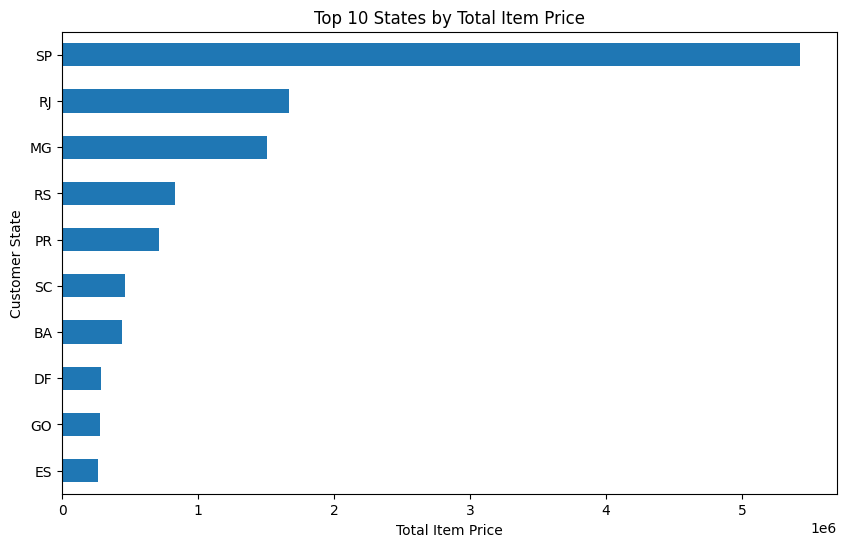

In [14]:
q1 = item_data.groupby('customer_state').agg(
    total_item_price=('price', 'sum'),
    order_count=('order_id', 'nunique')
)

q1 = q1.sort_values(
    by='total_item_price',
    ascending=False
).head(10)

print(q1)

q1.sort_values('total_item_price').plot(
    kind='barh',
    y='total_item_price',
    legend=False,
    figsize=(10, 6)
)

plt.title('Top 10 States by Total Item Price')
plt.xlabel('Total Item Price')
plt.ylabel('Customer State')
plt.show()

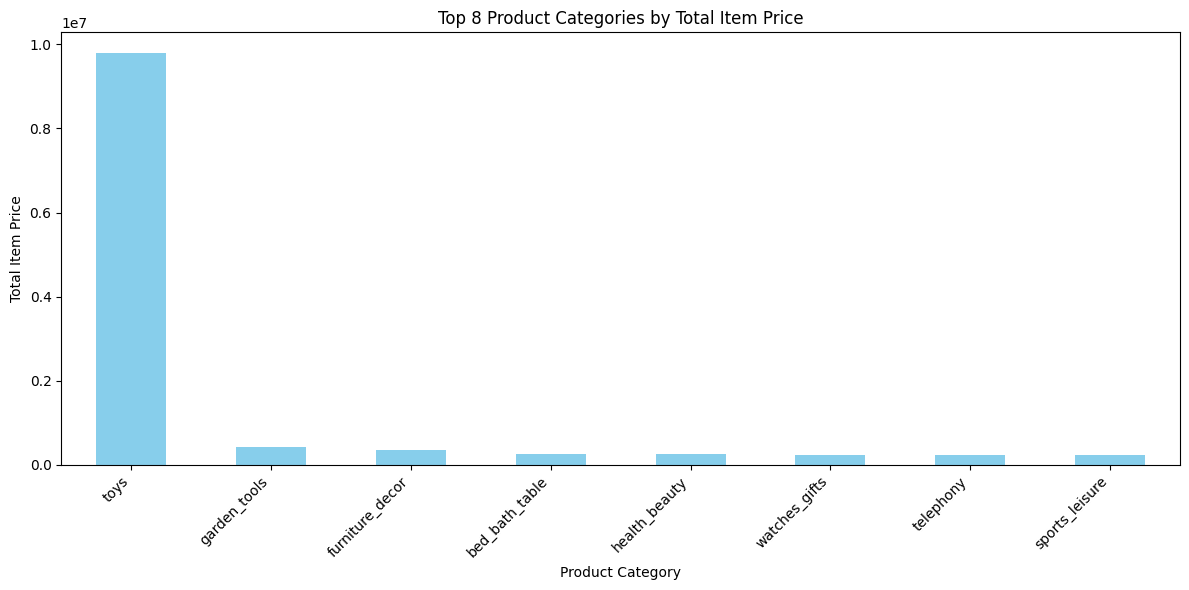

In [15]:
item_data['product_category_name'] = (
    item_data['product_category_name'].fillna('Unknown')
)

q2 = item_data.groupby(
    'product_category_name'
)['price'].sum().sort_values(
    ascending=False
).head(8)

q2.plot(
    kind='bar',
    figsize=(12, 6),
    color='skyblue'
)

plt.title('Top 8 Product Categories by Total Item Price')
plt.xlabel('Product Category')
plt.ylabel('Total Item Price')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

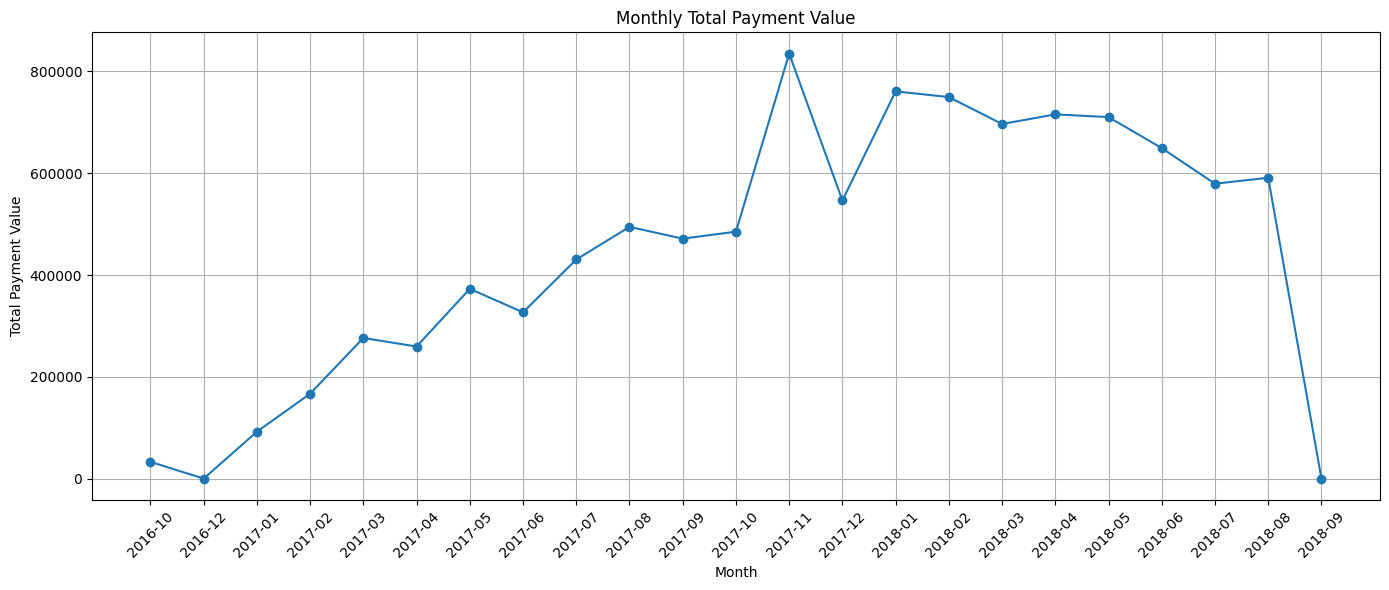

First observation: 2016-10-03 16:56:50
Last observation: 2018-09-03 09:06:57


In [16]:
payment_data['order_purchase_timestamp'] = pd.to_datetime(
    payment_data['order_purchase_timestamp']
)

payment_data['month'] = (
    payment_data['order_purchase_timestamp'].dt.to_period('M')
)

q3 = payment_data.groupby('month')['payment_value'].sum()

q3.index = q3.index.astype(str)

plt.figure(figsize=(14, 6))

plt.plot(
    q3.index,
    q3.values,
    marker='o'
)

plt.title('Monthly Total Payment Value')
plt.xlabel('Month')
plt.ylabel('Total Payment Value')
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()

print("First observation:", payment_data['order_purchase_timestamp'].min())
print("Last observation:", payment_data['order_purchase_timestamp'].max())

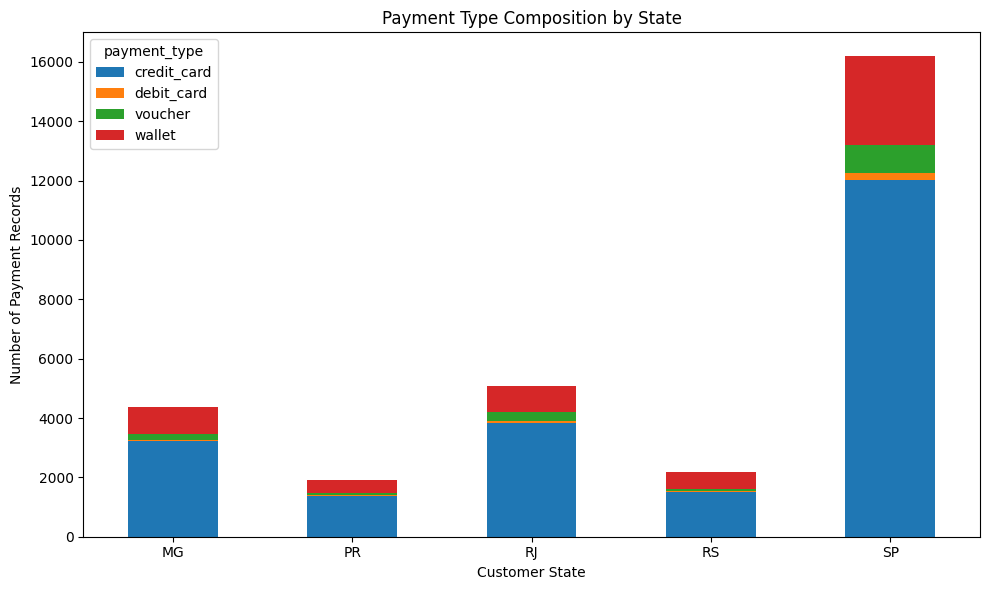

In [17]:
state_orders = item_data[
    ['customer_state', 'order_id']
].drop_duplicates()

top_states = state_orders.groupby(
    'customer_state'
)['order_id'].nunique().nlargest(5).index

q4_data = payment_data[
    payment_data['customer_state'].isin(top_states)
]

q4 = pd.crosstab(
    q4_data['customer_state'],
    q4_data['payment_type']
)

q4.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

plt.title('Payment Type Composition by State')
plt.xlabel('Customer State')
plt.ylabel('Number of Payment Records')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [19]:
print(item_data.columns.tolist())

['order_id', 'product_id', 'seller_id', 'price', 'shipping_charges', 'customer_id', 'order_purchase_timestamp', 'order_approved_at', 'customer_zip_code_prefix', 'customer_city', 'customer_state', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm', 'product_category_name']


In [20]:
print(order_items.columns.tolist())

['order_id', 'product_id', 'seller_id', 'price', 'shipping_charges']


                       order_count  mean_item_price  mean_shipping
product_category_name                                             
toys                         28697       341.354950      44.696205
health_beauty                 1038       236.314066      41.968208
bed_bath_table                 948       266.034810      42.280591
sports_leisure                 804       281.322139      43.064677
computers_accessories          746       272.540214      41.903485
furniture_decor                744       457.955645      43.958333
housewares                     586       289.984642      42.943686
watches_gifts                  489       498.701431      42.112474


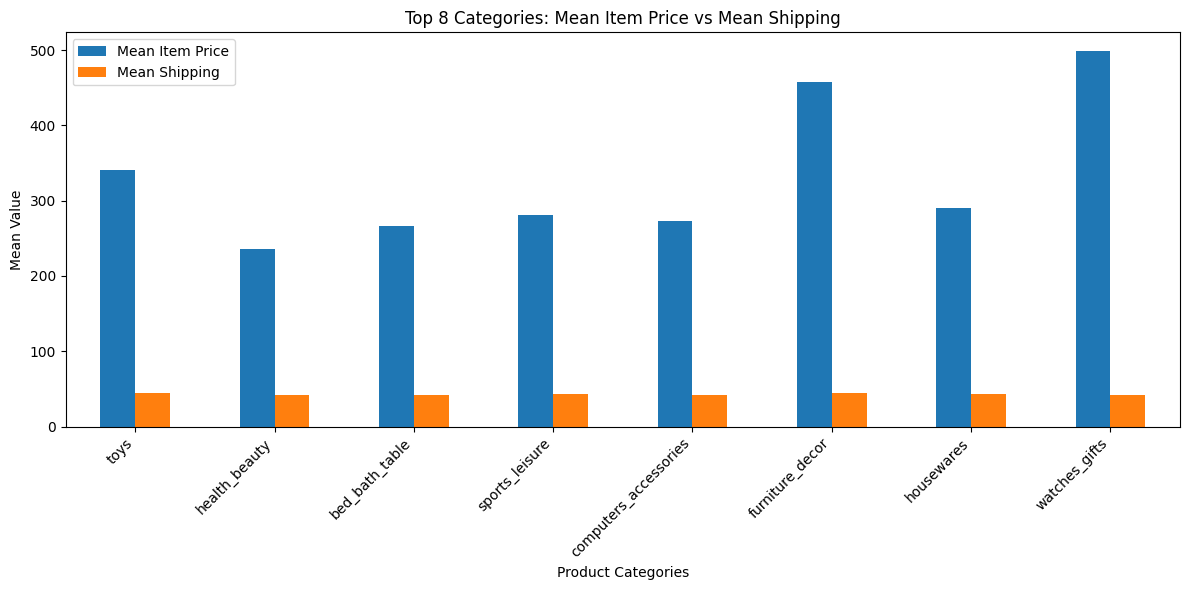

In [21]:
# Step 1: Handle missing product categories
item_data['product_category_name'] = (
    item_data['product_category_name'].fillna('Unknown')
)

# Step 2: Find the actual shipping column name
shipping_col = next(
    (col for col in item_data.columns
     if 'shipping' in col.lower() or 'freight' in col.lower()),
    None
)

# Step 3: Check whether shipping column was found
if shipping_col is None:
    print("Shipping column not found.")
    print("Available columns:", item_data.columns.tolist())

else:
    # Step 4: Group data category-wise
    q5 = item_data.groupby('product_category_name').agg(
        order_count=('order_id', 'nunique'),
        mean_item_price=('price', 'mean'),
        mean_shipping=(shipping_col, 'mean')
    )

    # Step 5: Select top 8 categories
    q5 = q5.sort_values(
        by='order_count',
        ascending=False
    ).head(8)

    # Step 6: Display result
    print(q5)

    # Step 7: Create grouped bar chart
    q5[['mean_item_price', 'mean_shipping']].plot(
        kind='bar',
        figsize=(12, 6)
    )

    plt.title('Top 8 Categories: Mean Item Price vs Mean Shipping')
    plt.xlabel('Product Categories')
    plt.ylabel('Mean Value')
    plt.xticks(rotation=45, ha='right')
    plt.legend(['Mean Item Price', 'Mean Shipping'])
    plt.tight_layout()
    plt.show()

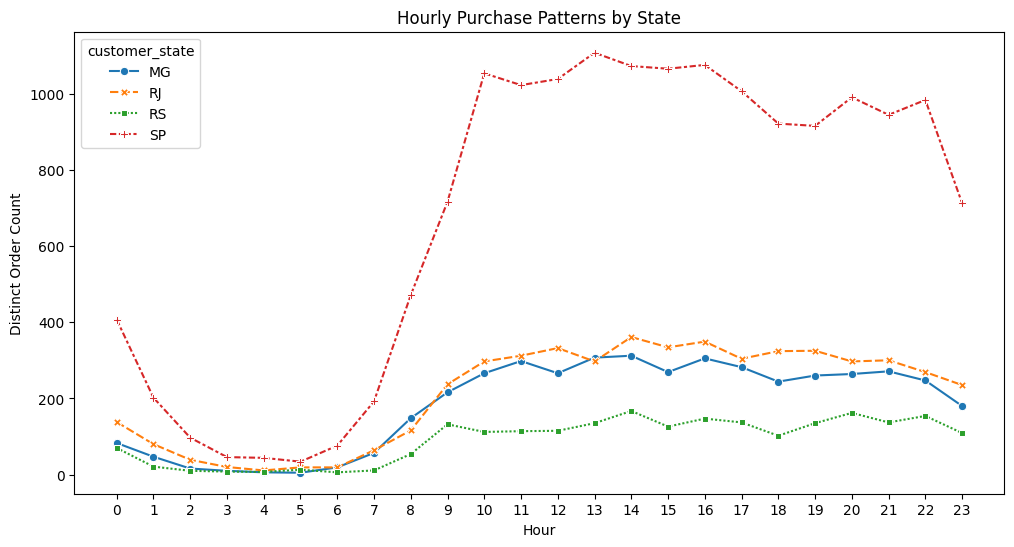

In [22]:
orders['order_purchase_timestamp'] = pd.to_datetime(
    orders['order_purchase_timestamp']
)

order_state = pd.merge(
    orders,
    customers[['customer_id', 'customer_state']],
    on='customer_id',
    how='left'
)

top4 = order_state.groupby(
    'customer_state'
)['order_id'].nunique().nlargest(4).index

order_state['hour'] = (
    order_state['order_purchase_timestamp'].dt.hour
)

q6 = order_state[
    order_state['customer_state'].isin(top4)
]

q6 = q6.groupby(
    ['hour', 'customer_state']
)['order_id'].nunique().reset_index()

q6_pivot = q6.pivot(
    index='hour',
    columns='customer_state',
    values='order_id'
).reindex(range(24), fill_value=0)

plt.figure(figsize=(12, 6))

sns.lineplot(data=q6_pivot, markers=True)

plt.title('Hourly Purchase Patterns by State')
plt.xlabel('Hour')
plt.ylabel('Distinct Order Count')
plt.xticks(range(24))
plt.show()

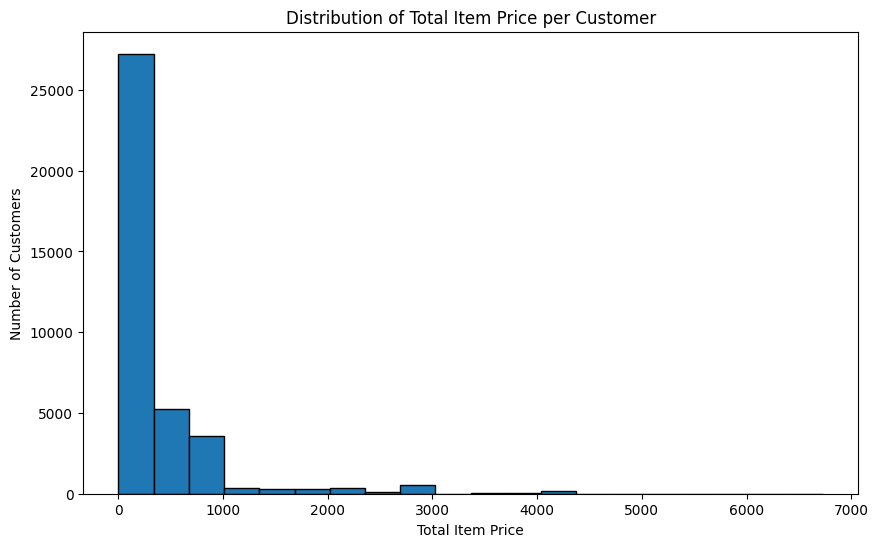

In [23]:
q7 = item_data.groupby(
    'customer_id'
)['price'].sum()

plt.figure(figsize=(10, 6))

plt.hist(q7, bins=20, edgecolor='black')

plt.title('Distribution of Total Item Price per Customer')
plt.xlabel('Total Item Price')
plt.ylabel('Number of Customers')

plt.show()

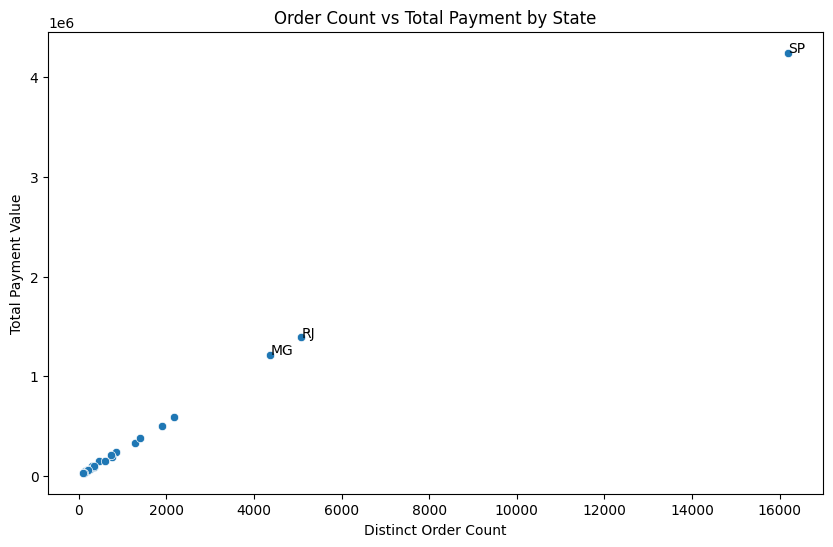

In [24]:
q8 = payment_data.groupby(
    'customer_state'
).agg(
    order_count=('order_id', 'nunique'),
    total_payment=('payment_value', 'sum')
).reset_index()

q8 = q8[q8['order_count'] >= 100]

top3 = q8.nlargest(3, 'total_payment')

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=q8,
    x='order_count',
    y='total_payment'
)

for _, row in top3.iterrows():
    plt.annotate(
        row['customer_state'],
        (row['order_count'], row['total_payment'])
    )

plt.title('Order Count vs Total Payment by State')
plt.xlabel('Distinct Order Count')
plt.ylabel('Total Payment Value')
plt.show()

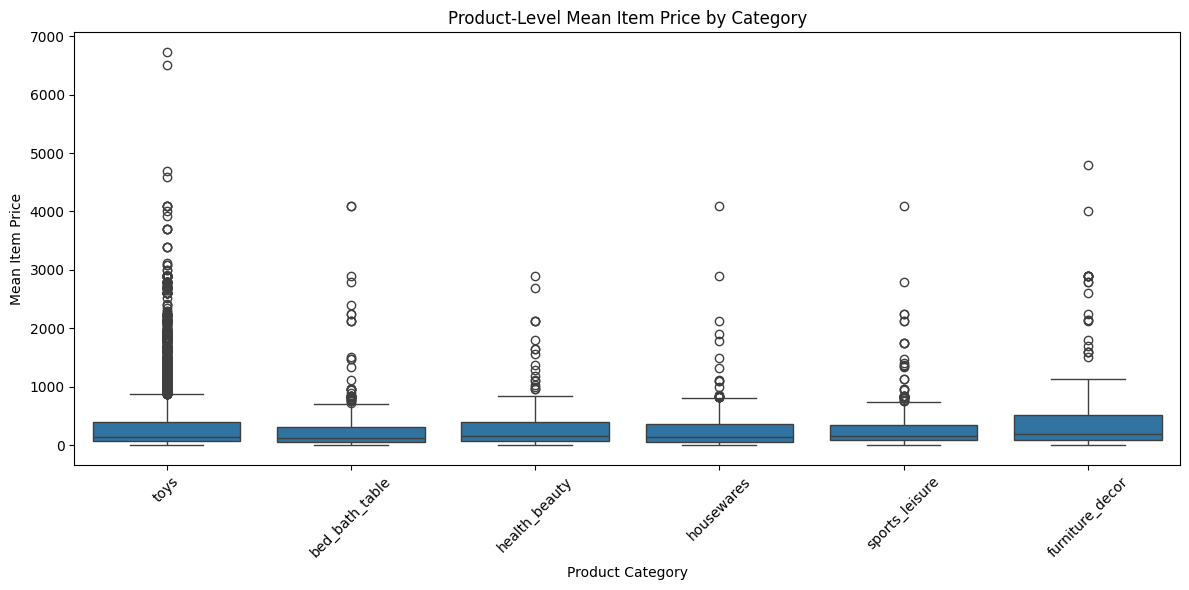

In [25]:
item_data['product_category_name'] = (
    item_data['product_category_name'].fillna('Unknown')
)

product_price = item_data.groupby(
    ['product_id', 'product_category_name']
)['price'].mean().reset_index()

top6 = product_price.groupby(
    'product_category_name'
)['product_id'].nunique().nlargest(6).index

q9 = product_price[
    product_price['product_category_name'].isin(top6)
]

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=q9,
    x='product_category_name',
    y='price'
)

plt.title('Product-Level Mean Item Price by Category')
plt.xlabel('Product Category')
plt.ylabel('Mean Item Price')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

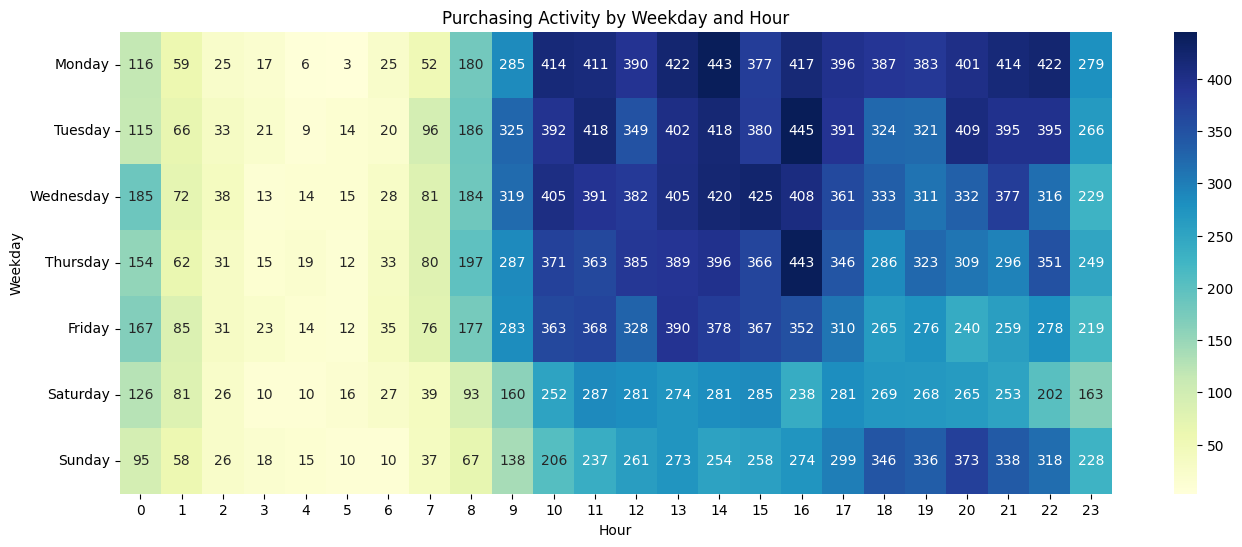

In [26]:
orders['order_purchase_timestamp'] = pd.to_datetime(
    orders['order_purchase_timestamp']
)

orders['weekday'] = (
    orders['order_purchase_timestamp'].dt.dayofweek
)

orders['hour'] = (
    orders['order_purchase_timestamp'].dt.hour
)

q10 = orders.groupby(
    ['weekday', 'hour']
)['order_id'].nunique().unstack(fill_value=0)

q10 = q10.reindex(
    index=range(7),
    columns=range(24),
    fill_value=0
)

q10.index = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

plt.figure(figsize=(16, 6))

sns.heatmap(
    q10,
    annot=True,
    fmt='d',
    cmap='YlGnBu'
)

plt.title('Purchasing Activity by Weekday and Hour')
plt.xlabel('Hour')
plt.ylabel('Weekday')
plt.show()

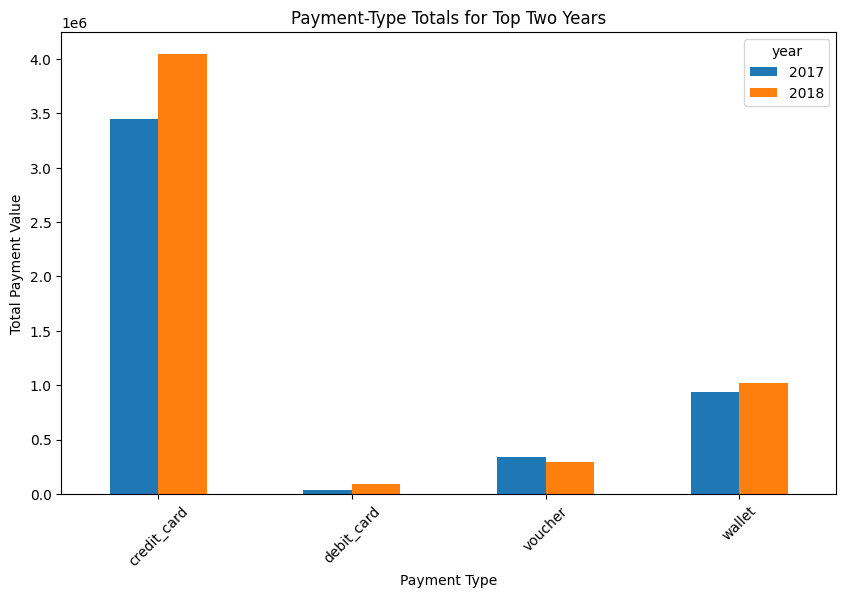

2018 2018-01-01 02:48:41 to 2018-09-03 09:06:57
2017 2017-01-05 12:01:20 to 2017-12-31 21:10:02


In [28]:
payment_data['year'] = (
    payment_data['order_purchase_timestamp'].dt.year
)

year_total = payment_data.groupby(
    'year'
)['payment_value'].sum().nlargest(2)

top_years = year_total.index

q12 = payment_data[
    payment_data['year'].isin(top_years)
]

q12 = q12.pivot_table(
    index='payment_type',
    columns='year',
    values='payment_value',
    aggfunc='sum',
    fill_value=0
)

q12.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Payment-Type Totals for Top Two Years')
plt.xlabel('Payment Type')
plt.ylabel('Total Payment Value')
plt.xticks(rotation=45)
plt.show()

for year in top_years:
    dates = payment_data.loc[
        payment_data['year'] == year,
        'order_purchase_timestamp'
    ]

    print(year, dates.min(), "to", dates.max())

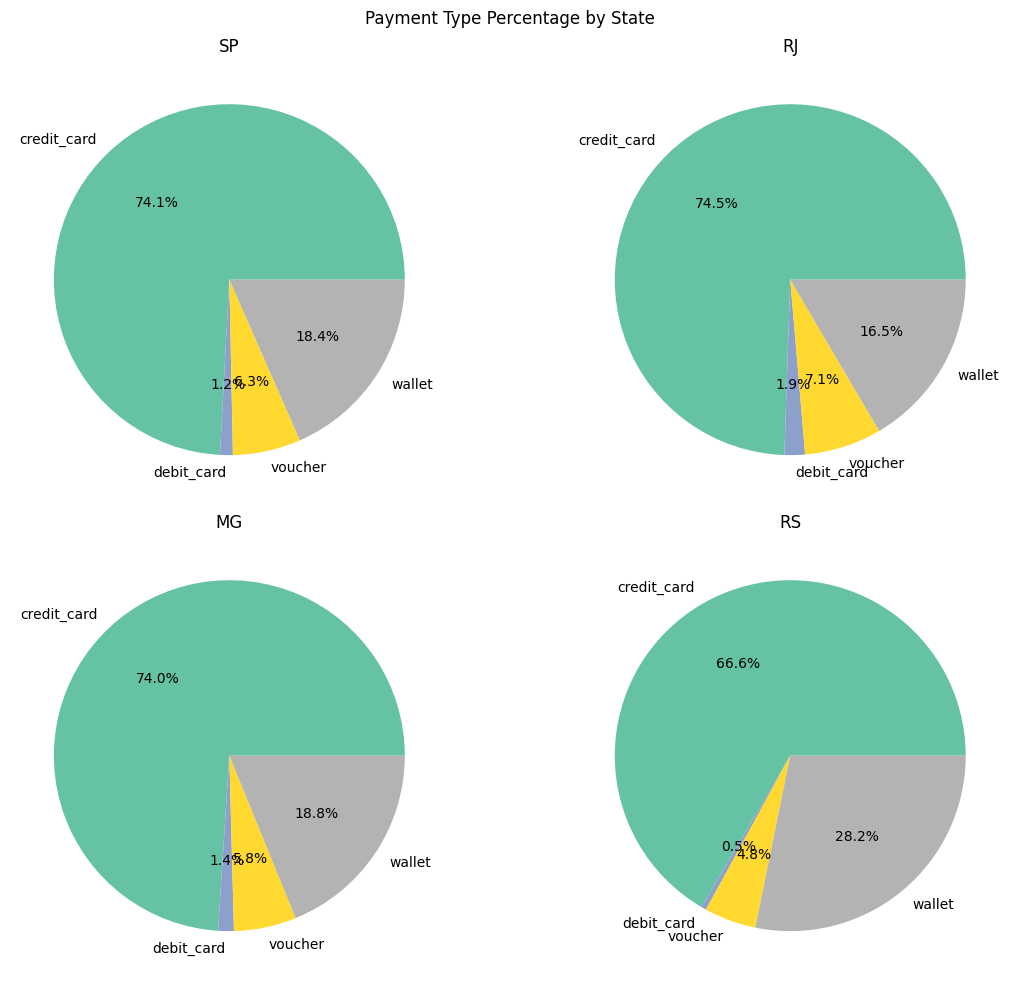

In [29]:
state_total = payment_data.groupby(
    'customer_state'
)['payment_value'].sum().nlargest(4)

top_states = state_total.index

q13 = payment_data[
    payment_data['customer_state'].isin(top_states)
]

payment_types = sorted(q13['payment_type'].dropna().unique())

colors = plt.cm.Set2(
    np.linspace(0, 1, len(payment_types))
)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, state in zip(axes.flatten(), top_states):

    data = q13[q13['customer_state'] == state]

    totals = data.groupby(
        'payment_type'
    )['payment_value'].sum().reindex(
        payment_types, fill_value=0
    )

    ax.pie(
        totals,
        labels=payment_types,
        autopct='%1.1f%%',
        colors=colors
    )

    ax.set_title(state)

plt.suptitle('Payment Type Percentage by State')
plt.tight_layout()
plt.show()

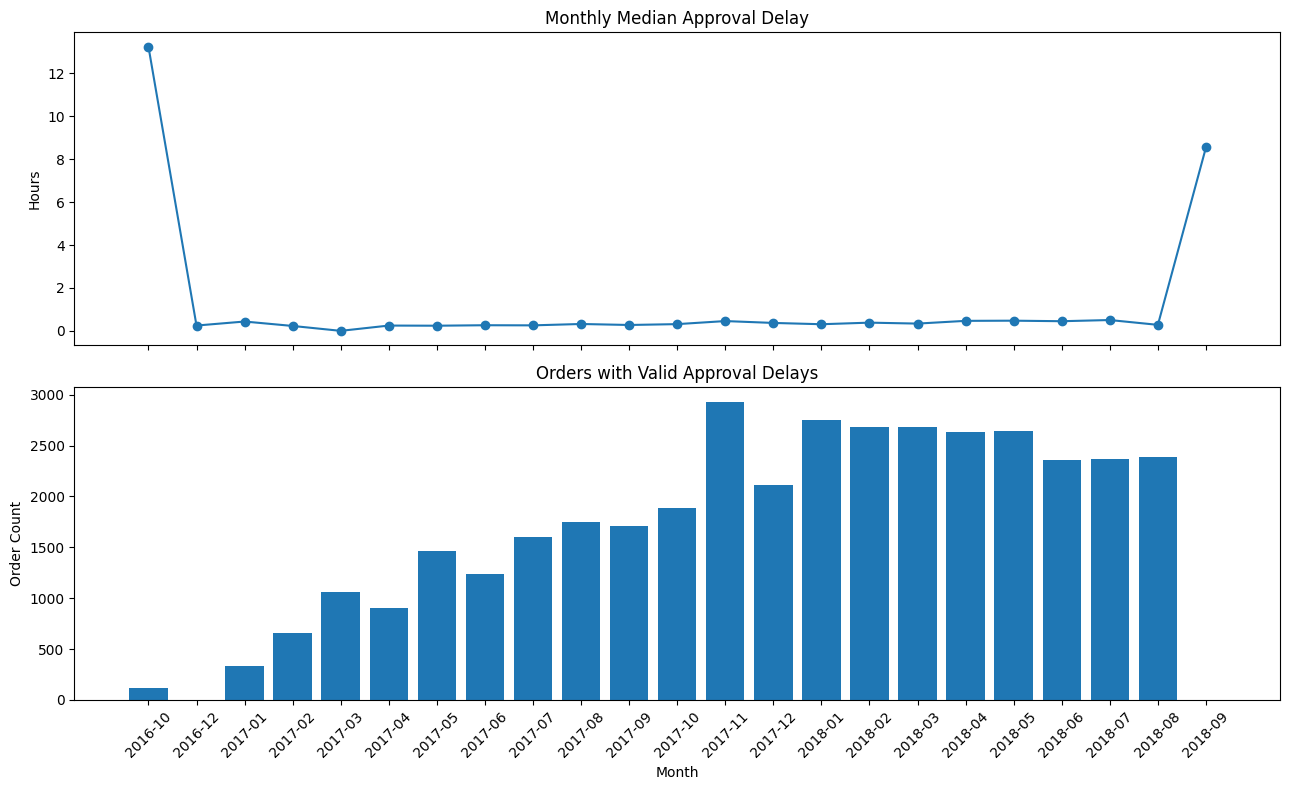

In [30]:
orders['order_approved_at'] = pd.to_datetime(
    orders['order_approved_at']
)

orders['approval_delay'] = (
    orders['order_approved_at'] -
    orders['order_purchase_timestamp']
).dt.total_seconds() / 3600

valid = orders[
    orders['approval_delay'].notna() &
    (orders['approval_delay'] >= 0)
].copy()

valid['month'] = (
    valid['order_purchase_timestamp'].dt.to_period('M')
)

q14 = valid.groupby('month').agg(
    median_delay=('approval_delay', 'median'),
    valid_orders=('order_id', 'nunique')
)

fig, axes = plt.subplots(
    2, 1,
    figsize=(13, 8),
    sharex=True
)

axes[0].plot(
    q14.index.astype(str),
    q14['median_delay'],
    marker='o'
)

axes[0].set_title('Monthly Median Approval Delay')
axes[0].set_ylabel('Hours')

axes[1].bar(
    q14.index.astype(str),
    q14['valid_orders']
)

axes[1].set_title('Orders with Valid Approval Delays')
axes[1].set_ylabel('Order Count')
axes[1].set_xlabel('Month')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

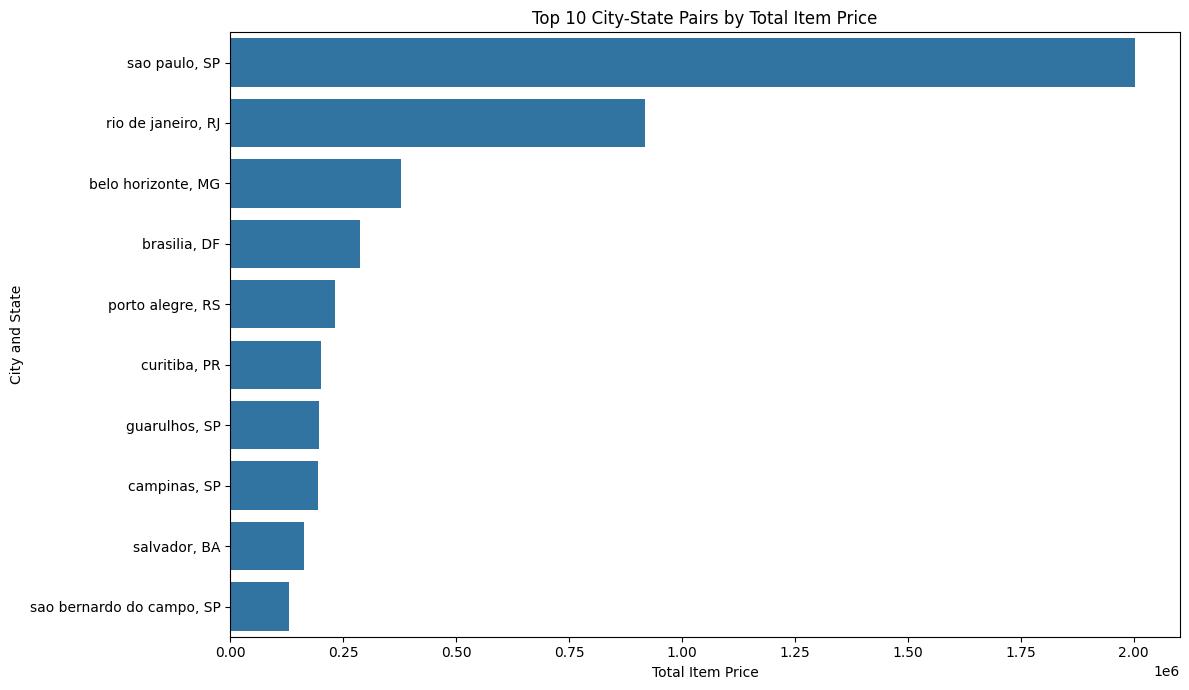

In [31]:
q15 = item_data.groupby(
    ['customer_state', 'customer_city']
).agg(
    order_count=('order_id', 'nunique'),
    total_item_price=('price', 'sum')
).reset_index()

q15 = q15[q15['order_count'] >= 30]

q15 = q15.nlargest(10, 'total_item_price').copy()

q15['city_state'] = (
    q15['customer_city'] + ', ' + q15['customer_state']
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=q15,
    x='total_item_price',
    y='city_state'
)

plt.title('Top 10 City-State Pairs by Total Item Price')
plt.xlabel('Total Item Price')
plt.ylabel('City and State')
plt.tight_layout()
plt.show()

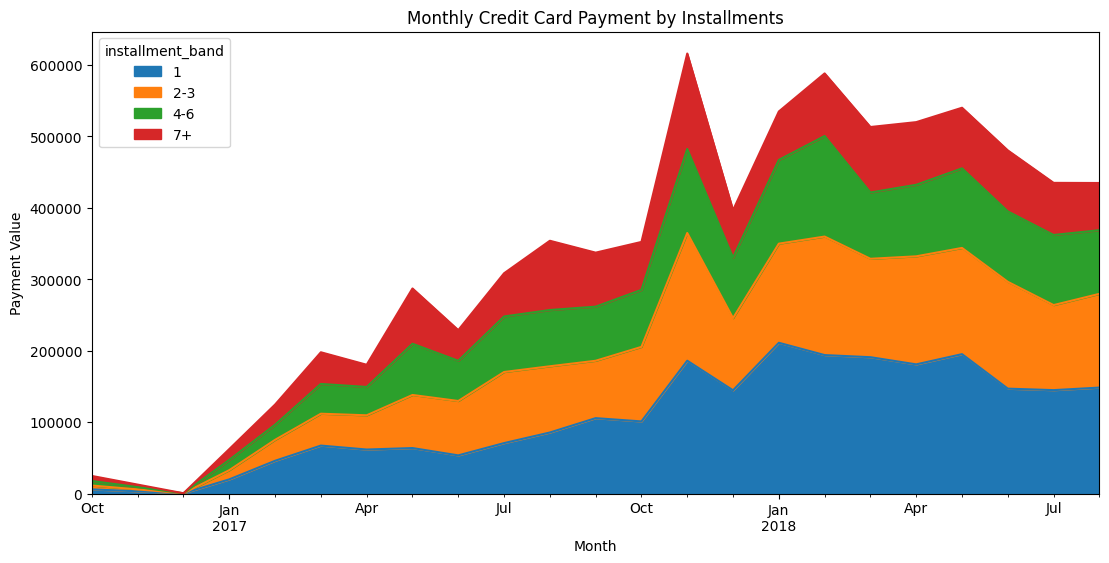

In [32]:
credit = payment_data[
    payment_data['payment_type'] == 'credit_card'
].copy()

credit = credit[
    credit['payment_installments'].notna() &
    (credit['payment_installments'] > 0)
]

credit['installment_band'] = pd.cut(
    credit['payment_installments'],
    bins=[0, 1, 3, 6, float('inf')],
    labels=['1', '2-3', '4-6', '7+']
)

credit['month'] = (
    credit['order_purchase_timestamp'].dt.to_period('M')
)

q16 = credit.pivot_table(
    index='month',
    columns='installment_band',
    values='payment_value',
    aggfunc='sum',
    observed=False
).fillna(0)

q16.plot(
    kind='area',
    stacked=True,
    figsize=(13, 6)
)

plt.title('Monthly Credit Card Payment by Installments')
plt.xlabel('Month')
plt.ylabel('Payment Value')
plt.show()

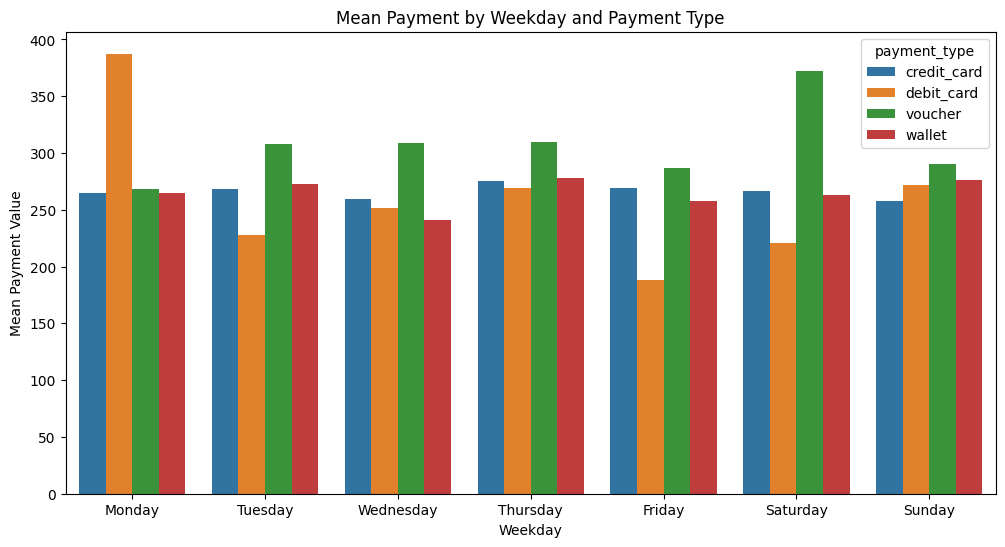

In [34]:
payment_data['weekday'] = (
    payment_data['order_purchase_timestamp'].dt.dayofweek
)

payment_data['weekday_name'] = payment_data[
    'weekday'
].map({
    0: 'Monday',
    1: 'Tuesday',
    2: 'Wednesday',
    3: 'Thursday',
    4: 'Friday',
    5: 'Saturday',
    6: 'Sunday'
})

q18 = payment_data.groupby(
    ['weekday_name', 'payment_type']
).agg(
    mean_payment=('payment_value', 'mean'),
    order_count=('order_id', 'nunique')
).reset_index()

q18 = q18[q18['order_count'] >= 20]

weekday_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

plt.figure(figsize=(12, 6))

sns.barplot(
    data=q18,
    x='weekday_name',
    y='mean_payment',
    hue='payment_type',
    order=weekday_order,
    errorbar=None
)

plt.title('Mean Payment by Weekday and Payment Type')
plt.xlabel('Weekday')
plt.ylabel('Mean Payment Value')
plt.show()

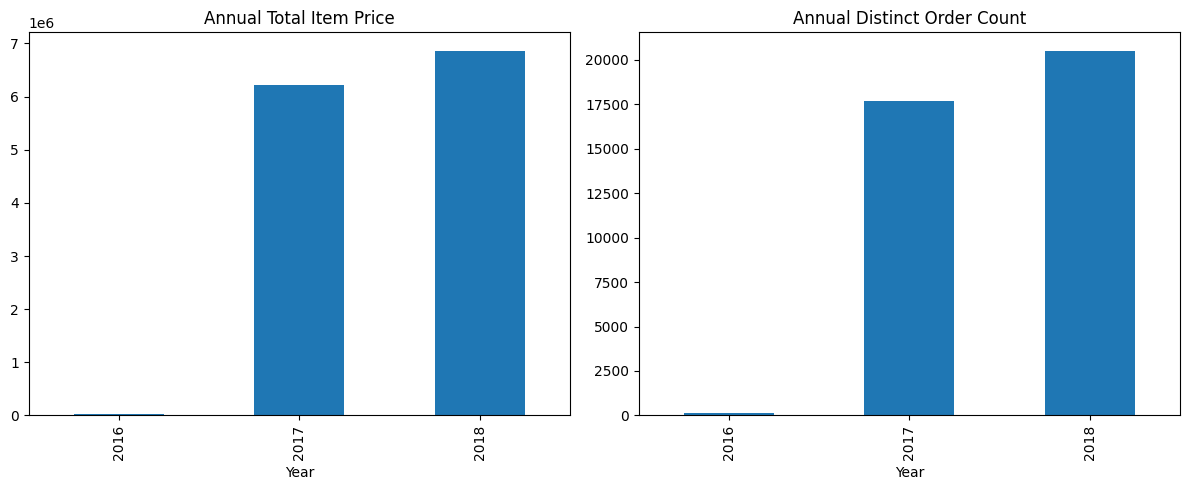

      total_item_price  order_count
year                               
2016           36712.0          114
2017         6209478.0        17658
2018         6865642.0        20507


In [35]:
orders['year'] = (
    orders['order_purchase_timestamp'].dt.year
)

annual_data = pd.merge(
    orders[['order_id', 'year']],
    order_items[['order_id', 'price']],
    on='order_id',
    how='inner'
)

annual_extracts = []

for year in [2016, 2017, 2018]:
    extract = annual_data[
        annual_data['year'] == year
    ].copy()

    annual_extracts.append(extract)

combined = pd.concat(
    annual_extracts,
    ignore_index=True
).drop_duplicates(
    subset=['order_id', 'year']
)

q19 = combined.groupby('year').agg(
    total_item_price=('price', 'sum'),
    order_count=('order_id', 'nunique')
).reindex([2016, 2017, 2018])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

q19['total_item_price'].plot(
    kind='bar',
    ax=axes[0]
)

axes[0].set_title('Annual Total Item Price')
axes[0].set_xlabel('Year')

q19['order_count'].plot(
    kind='bar',
    ax=axes[1]
)

axes[1].set_title('Annual Distinct Order Count')
axes[1].set_xlabel('Year')

plt.tight_layout()
plt.show()

print(q19)

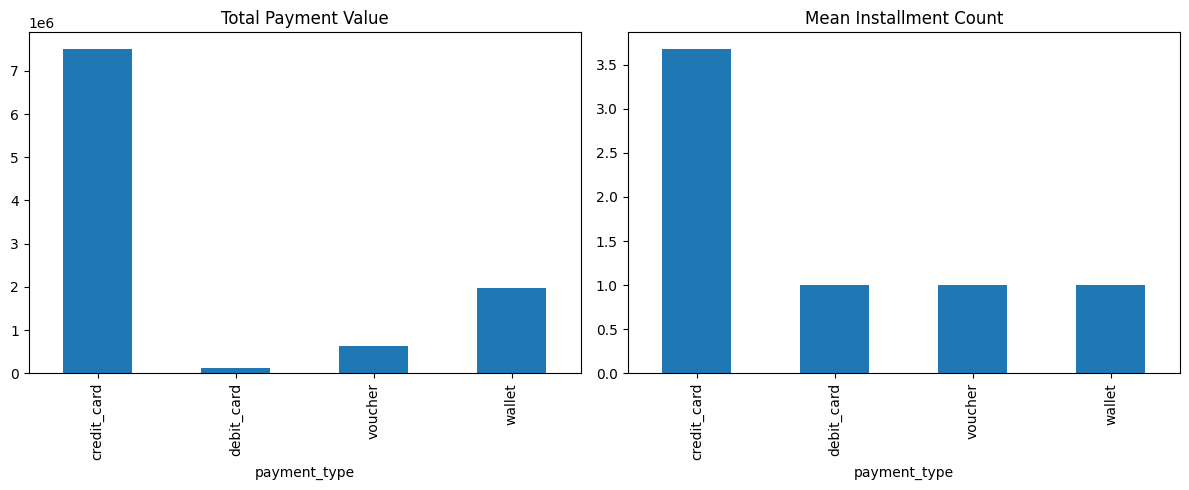

              total_payment  mean_installments
payment_type                                  
credit_card       7516504.0           3.684345
debit_card         130174.0           1.000000
voucher            637168.0           1.000000
wallet            1963594.0           1.000000


In [36]:
payment_extracts = []

for ptype in payments['payment_type'].dropna().unique():

    extract = payments[
        payments['payment_type'] == ptype
    ].copy()

    payment_extracts.append(extract)

combined_payments = pd.concat(
    payment_extracts,
    ignore_index=True
).drop_duplicates()

q20 = combined_payments.groupby(
    'payment_type'
).agg(
    total_payment=('payment_value', 'sum'),
    mean_installments=('payment_installments', 'mean')
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

q20['total_payment'].plot(
    kind='bar',
    ax=axes[0]
)

axes[0].set_title('Total Payment Value')

q20['mean_installments'].plot(
    kind='bar',
    ax=axes[1]
)

axes[1].set_title('Mean Installment Count')

plt.tight_layout()
plt.show()

print(q20)